In [1]:
from mlxtend.frequent_patterns import apriori, association_rules
import pandas as pd


In [2]:
data = {
    'transaction_id': [1, 2, 3, 4, 5],
    'item': [
        ['A', 'B', 'C'],
        ['B', 'C'],
        ['A', 'C'],
        ['A', 'B', 'C', 'D'],
        ['B', 'C', 'D']
    ]
}
df = pd.DataFrame(data)
one_hot_encoded_df = df['item'].str.join('|').str.get_dummies()
frequent_itemsets = apriori(one_hot_encoded_df, min_support=0.2, use_colnames=True)

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.7)

print(f"Frequent Itemsets:", frequent_itemsets)

Frequent Itemsets:     support      itemsets
0       0.6           (A)
1       0.8           (B)
2       1.0           (C)
3       0.4           (D)
4       0.4        (B, A)
5       0.6        (C, A)
6       0.2        (D, A)
7       0.8        (C, B)
8       0.4        (D, B)
9       0.4        (D, C)
10      0.4     (B, C, A)
11      0.2     (D, B, A)
12      0.2     (D, C, A)
13      0.4     (D, C, B)
14      0.2  (D, B, C, A)


c:\Users\mazen\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
c:\Users\mazen\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:186: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


In [3]:
print(f"rules:", rules)

rules:    antecedents consequents  antecedent support  consequent support  support  \
0          (A)         (C)                 0.6                 1.0      0.6   
1          (C)         (B)                 1.0                 0.8      0.8   
2          (B)         (C)                 0.8                 1.0      0.8   
3          (D)         (B)                 0.4                 0.8      0.4   
4          (D)         (C)                 0.4                 1.0      0.4   
5       (A, B)         (C)                 0.4                 1.0      0.4   
6       (D, A)         (B)                 0.2                 0.8      0.2   
7       (D, A)         (C)                 0.2                 1.0      0.2   
8       (D, C)         (B)                 0.4                 0.8      0.4   
9       (D, B)         (C)                 0.4                 1.0      0.4   
10         (D)      (C, B)                 0.4                 0.8      0.4   
11   (D, A, B)         (C)                 0.

In [4]:
print(f"Association Rules:\n{rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]}")

Association Rules:
   antecedents consequents  support  confidence  lift
0          (A)         (C)      0.6         1.0  1.00
1          (C)         (B)      0.8         0.8  1.00
2          (B)         (C)      0.8         1.0  1.00
3          (D)         (B)      0.4         1.0  1.25
4          (D)         (C)      0.4         1.0  1.00
5       (A, B)         (C)      0.4         1.0  1.00
6       (D, A)         (B)      0.2         1.0  1.25
7       (D, A)         (C)      0.2         1.0  1.00
8       (D, C)         (B)      0.4         1.0  1.25
9       (D, B)         (C)      0.4         1.0  1.00
10         (D)      (C, B)      0.4         1.0  1.25
11   (D, A, B)         (C)      0.2         1.0  1.00
12   (D, C, A)         (B)      0.2         1.0  1.25
13      (D, A)      (C, B)      0.2         1.0  1.25


In [5]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import IsolationForest

Text(0.5, 1.0, 'Isolation Forest Outliers')

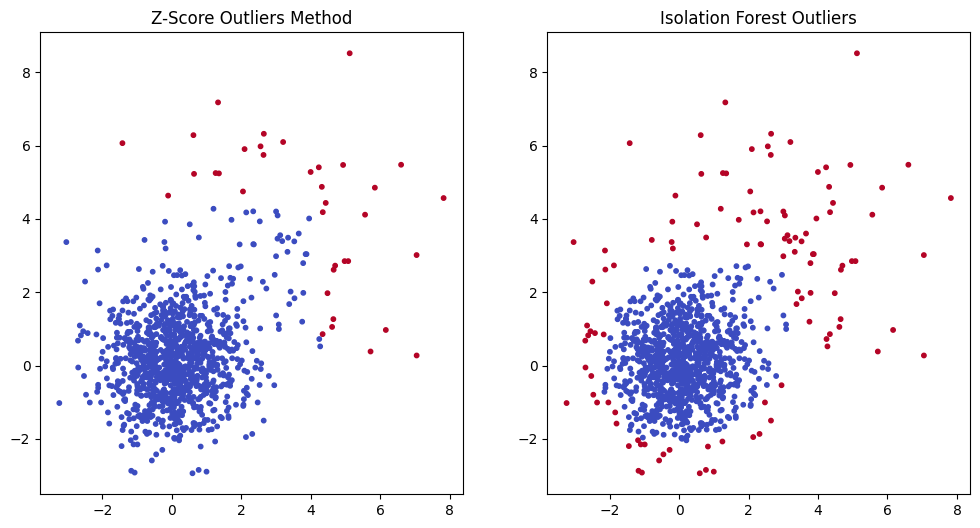

In [6]:
np.random.seed(42)
x = np.random.randn(1000, 2)
x = np.r_[x, np.random.randn(100, 2) * 2 + [3, 3]]

def zscore_outliers(data, threshold=3):
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    z_scores = np.abs((data - mean) / std)
    return np.any(z_scores > threshold, axis=1)

iso_forest = IsolationForest(contamination=0.1, random_state=42)
iso_forest_outliers_ = iso_forest.fit_predict(x) == -1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
ax1.scatter(x[:, 0], x[:, 1], c=zscore_outliers(x), cmap='coolwarm', s=10)
ax1.set_title("Z-Score Outliers Method")
ax2.scatter(x[:, 0], x[:, 1], c=iso_forest_outliers_, cmap='coolwarm', s=10)
ax2.set_title("Isolation Forest Outliers")

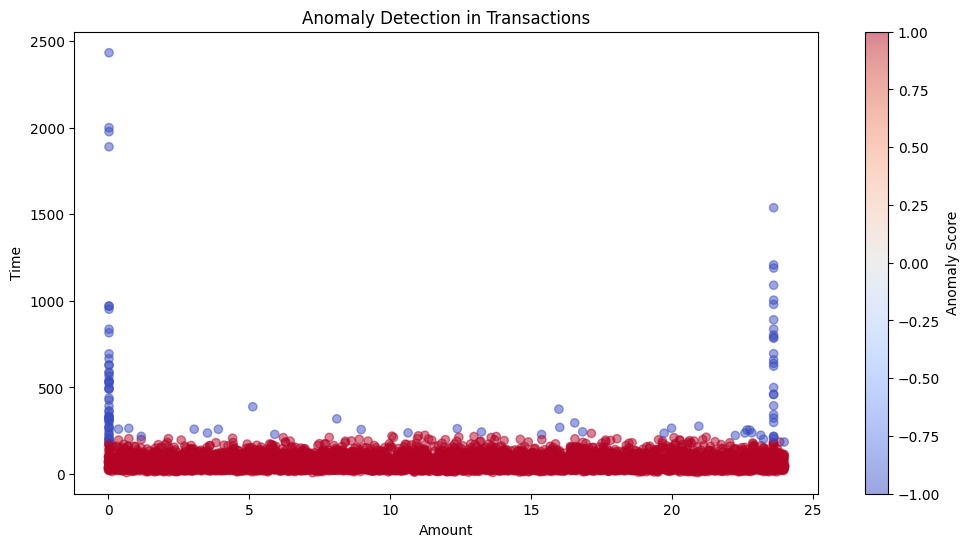

Anomalies detected: 101


In [8]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
n_samples = 10000

amount = np.random.lognormal(mean=4, sigma=0.5, size=n_samples)
time = np.random.uniform(low=0, high=24, size=n_samples)

fraud_amount = np.random.lognormal(mean=6, sigma=1, size=100)
fraud_time = np.random.choice([np.random.uniform(low=0, high=3), np.random.uniform(low=22, high=24)], size=100)

amount = np.concatenate([amount, fraud_amount])
time = np.concatenate([time, fraud_time])

data = pd.DataFrame({"amount": amount, "time": time})
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

iso_forest = IsolationForest(contamination=0.01, random_state=42)
predictions = iso_forest.fit_predict(data_scaled)

data['anomaly'] = predictions


plt.figure(figsize=(12, 6))
plt.scatter(data['time'], data['amount'], c=data['anomaly'], cmap='coolwarm', alpha=0.5)
plt.xlabel('Amount')
plt.ylabel('Time')
plt.title('Anomaly Detection in Transactions')
plt.colorbar(label='Anomaly Score')
plt.show()

print("Anomalies detected:", data[data['anomaly'] == -1].shape[0])